## Pryngles Tutorial: Evolution

In this tutorial we introduce the basic elements of the newest version of Pryngles (>=1.0.x).

In [1]:
from pryngles import *
from IPython.display import Image
version

'0.9.0'

## A simple system

The most simple system:

<IPython.core.display.Javascript object>


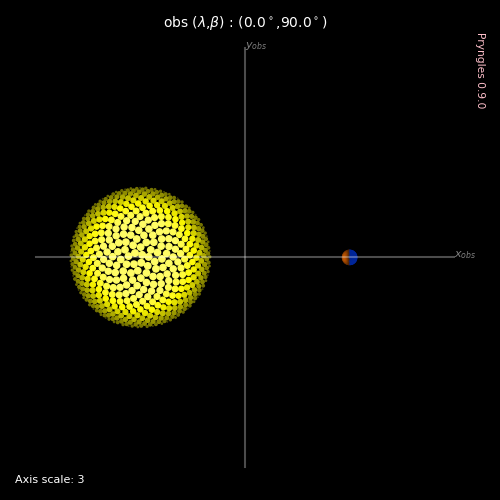

In [2]:
sys=System()
S=sys.add()
P=sys.add("Planet",primary=S,radius=0.1,a=3)
sys.initialize_simulation()
sys.spangle_system()
sys.sg.plot2d();

Focus on planet:

<IPython.core.display.Javascript object>


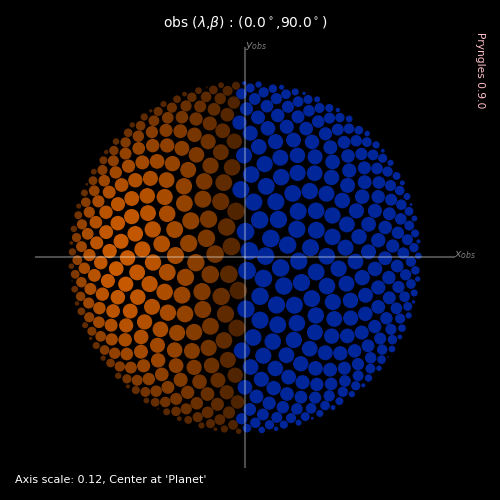

In [3]:
sys=System()
S=sys.add()
P=sys.add("Planet",primary=S,radius=0.1,a=3)
sys.initialize_simulation()
sys.spangle_system()
sys.sg.plot2d(include=["Planet"]);

Add information to plot:

<IPython.core.display.Javascript object>


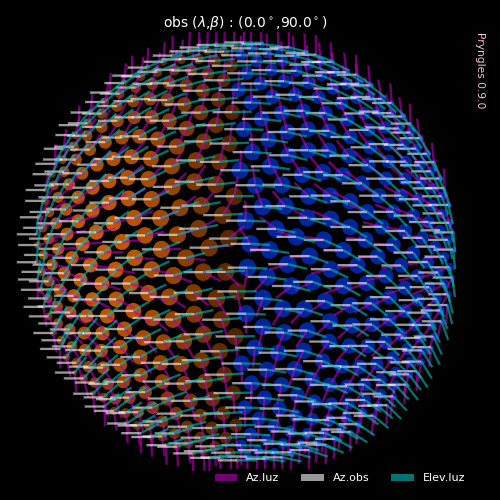

In [4]:
sys=System()
S=sys.add()
P=sys.add("Planet",primary=S,radius=0.1,a=3)
sys.initialize_simulation()
sys.spangle_system()
sys.sg.plot2d(include=["Planet"],show_azim=True);

DataFrame with key information:

In [5]:
sys.data[SPANGLER_KEY_ORDERING]

,name,spangle_type,x_ecl,y_ecl,z_ecl,ns_ecl,azim_obs,n_obs,d_obs,asp_obs,...,az_luz,cosf_luz,z_cen_luz,azim_obs_luz,dsp,unset,hidden,source,intersect,above
0,Star,6,-1.543426,-0.010637,-0.9990,"[-0.04342638520937469, -0.010637155054194778, ...",3.141593,"[0, 0, 1]",inf,1.0,...,3.381810,-0.999000,-inf,0.000000,0.127321,False,False,True,False,False
1,Star,6,-1.432126,-0.037204,-0.9970,"[0.06787377443992139, -0.03720417642252864, -0...",3.141593,"[0, 0, 1]",inf,1.0,...,5.781773,-0.997000,-inf,0.000000,0.127321,False,False,True,False,False
2,Star,6,-1.532152,0.094558,-0.9950,"[-0.03215153060099353, 0.09455833691437968, -0...",3.141593,"[0, 0, 1]",inf,1.0,...,1.898551,-0.995000,-inf,0.000000,0.127321,False,False,True,False,False
3,Star,6,-1.547501,-0.108142,-0.9930,"[-0.047500870193838717, -0.10814188518251444, ...",3.141593,"[0, 0, 1]",inf,1.0,...,4.298514,-0.993000,-inf,0.000000,0.127321,False,False,True,False,False
4,Star,6,-1.377517,0.054008,-0.9910,"[0.12248341269307314, 0.05400753294734299, -0....",3.141593,"[0, 0, 1]",inf,1.0,...,0.415292,-0.991000,-inf,0.000000,0.127321,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1969,Planet,0,1.490739,-0.009666,0.0991,"[-0.09261007792143446, -0.09665595412278351, 0...",3.141593,"[0, 0, 1]",inf,1.0,...,1.473570,0.092610,-3.0,3.952880,0.012732,False,False,False,True,False
1970,Planet,0,1.511786,0.000769,0.0993,"[0.11786383089317873, 0.0076887819050877396, 0...",3.141593,"[0, 0, 1]",inf,1.0,...,1.578539,-0.117864,-3.0,0.065600,0.012732,False,False,False,True,False
1971,Planet,0,1.492212,0.006253,0.0995,"[-0.07788013621256241, 0.06252746903171799, 0....",3.141593,"[0, 0, 1]",inf,1.0,...,1.633555,0.077880,-3.0,2.462657,0.012732,False,False,False,True,False
1972,Planet,0,1.501177,-0.007650,0.0997,"[0.011771779650471199, -0.07650114511470073, 0...",3.141593,"[0, 0, 1]",inf,1.0,...,1.494215,-0.011772,-3.0,4.864618,0.012732,False,False,False,True,False


## Exoring in the new Pryngles

Add a ring:

<IPython.core.display.Javascript object>


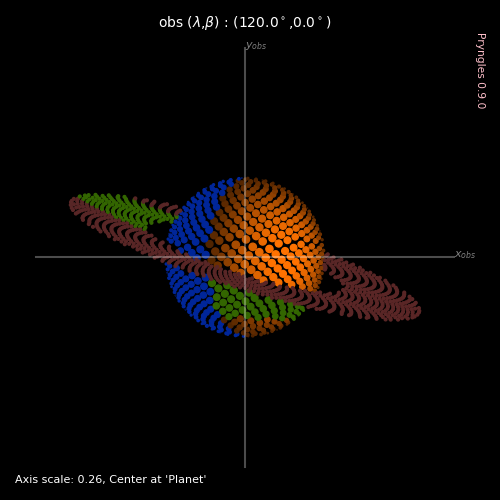

In [6]:
sys=System()
S=sys.add()
P=sys.add("Planet",primary=S,radius=0.1,a=3)
R=sys.add("Ring",primary=P,
          fi=1.3,fe=2.3,
          i=-20*Consts.deg,roll=0*Consts.deg)
sys.initialize_simulation()
sys.spangle_system()
sys.update_perspective(n_obs=Science.direction(120,0))
sys.sg.plot2d(include=["Planet","Ring"],show_azim=False);

Special variable with transit conditions:

In [ ]:
cond=(sys.data.transit_mask_obs!=0)
sys.data.loc[cond,["transit_mask_obs","transit_rho_obs"]]

Highlights points in planet seing through rings:

<IPython.core.display.Javascript object>


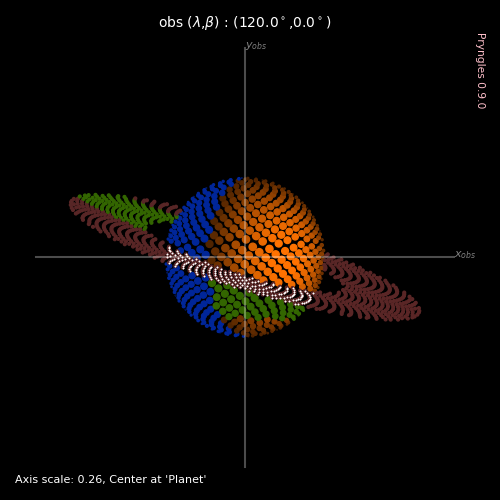

(-1.2990381865589573, -0.00021995947315096279)

In [8]:
cond=(sys.data.transit_mask_obs & sys.sg.body_bit("Planet"))!=0
sys.sg.plot2d(include=["Planet","Ring"],highlight=(cond,dict()))

Highlight points in partial shadow:

<IPython.core.display.Javascript object>


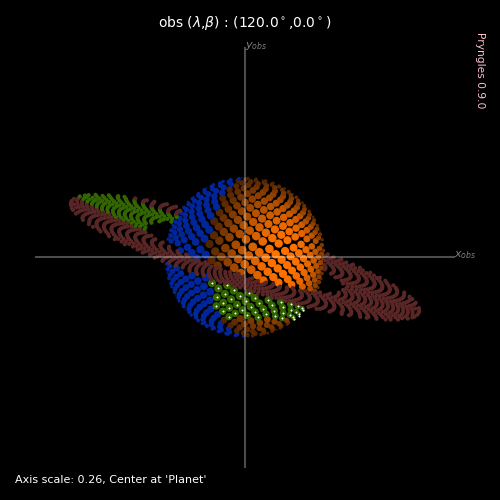

In [9]:
cond=((sys.data.hidden_mask_luz & sys.sg.body_bit("Ring"))!=0)&\
     (sys.data.visible)
sys.sg.plot2d(include=["Planet","Ring"],highlight=(cond,dict()));

Show points not visible by observer because they are behind the rings, but still they are illuminated by the source of light:

<IPython.core.display.Javascript object>


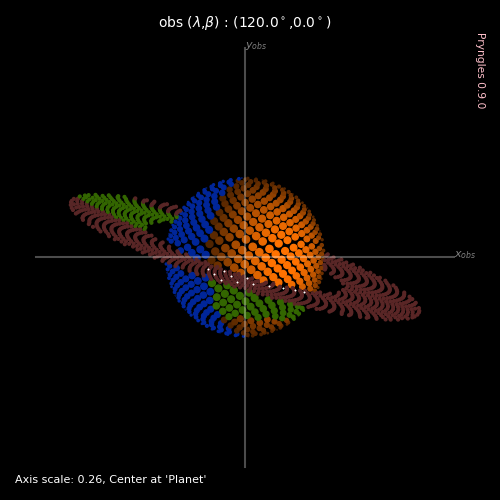

In [10]:
cond=((sys.data.hidden_mask_obs & sys.sg.body_bit("Ring"))!=0)&(~sys.data.visible)&(sys.data.illuminated)
sys.sg.plot2d(include=["Planet","Ring"],highlight=(cond,dict()));

## Exomoons in the new Pryngles

System with an exomoon:

<IPython.core.display.Javascript object>


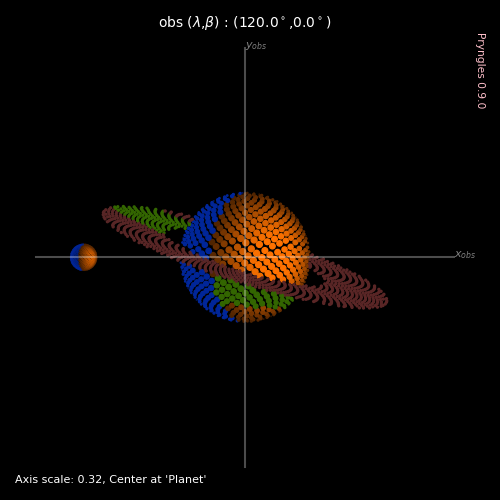

(-0.7410254846667391, -0.00021995947315096279)

In [11]:
sys=System()

S=sys.add()
P=sys.add("Planet",primary=S,radius=0.1,a=3)
R=sys.add("Ring",primary=P,
          fi=1.3,fe=2.3,
          i=-20*Consts.deg,roll=0*Consts.deg)

M=sys.add("Planet",name="Moon",primary=P,radius=0.02,a=0.5,M=90*Consts.deg)

sys.initialize_simulation()
sys.spangle_system()
sys.update_perspective(n_obs=Science.direction(120,0))
sys.sg.plot2d(include=["Planet","Moon","Ring"],show_azim=False)

Check orbit:

<IPython.core.display.Javascript object>


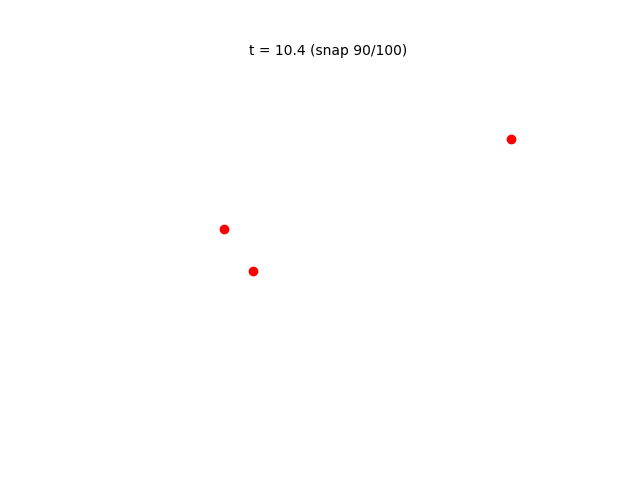

100%|██████████| 100/100 [00:00<00:00, 830.59it/s]


In [12]:
Plot.animate_rebound(sys.sim,filename="figures/system-animate.gif")
#Image(open("figures/system-animate.gif","rb").read())

Integrate the system:

<IPython.core.display.Javascript object>


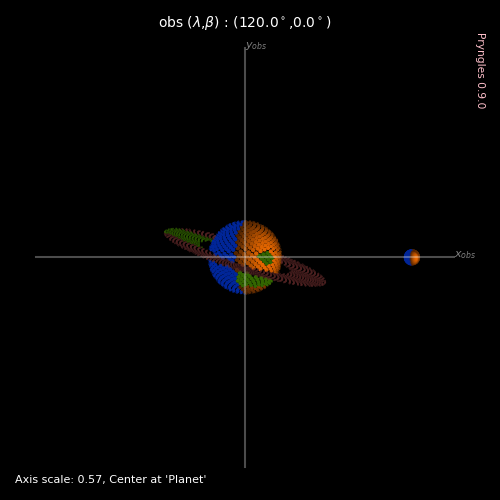

In [13]:
sys.integrate(2)
sys.update_perspective()
sys.sg.plot2d(include=["Planet","Moon","Ring"]);

Animate the visualization:

  0%|          | 0/10 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>


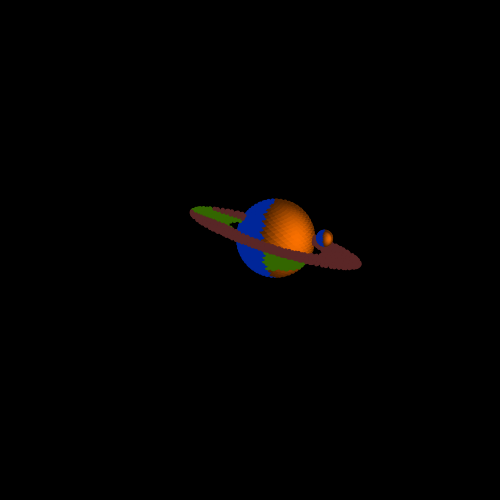

100%|██████████| 10/10 [00:14<00:00,  1.49s/it]


In [14]:
from tqdm import tqdm
for i,t in enumerate(tqdm(np.linspace(0,2,10))):
    sys.integrate(t)
    sys.update_perspective()
    if i==0:
        del sys.sg.fig2d
    sys.sg.plot2d(include=["Planet","Moon","Ring"],newfig=False)
    if i==0:
        camera=Camera(sys.sg.fig2d)
    else:
        camera.snap()

Save animation:

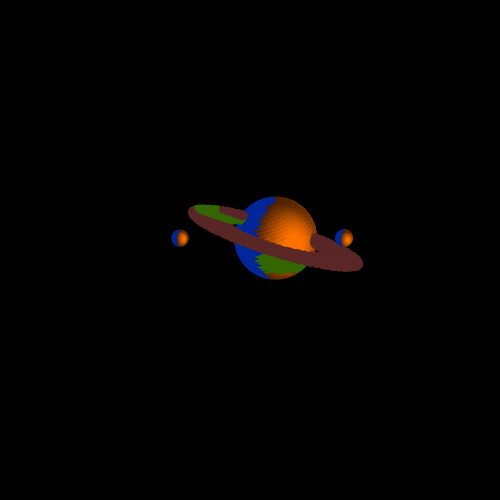

In [15]:
anim=camera.animate(interval=300,repeat=True,blit=False)
anim.save("figures/planet-moon-animation.gif")
Image(open("figures/planet-moon-animation.gif","rb").read())

Done!